In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Plots nalla vrithiyil kanikkan
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [4]:
# 1. Check missing values in each column
print("Missing values before cleaning:\n", df.isnull().sum())

# 2. Drop rows with missing values in critical columns
df = df.dropna(subset=["pickup", "fare", "distance", "total"])

# 3. Impute categorical columns with mode
for col in df.select_dtypes(include=["object", "category", "string"]).columns:
  df[col] = df[col].fillna(df[col].mode()[0])

# 4. Impute remaining numerical columns with median
for col in df.select_dtypes(include=["number"]).columns:
  df[col] = df[col].fillna(df[col].median())

# 5. Verify no missing values remain
print("\nMissing values after cleaning:\n", df.isnull().sum())

Missing values before cleaning:
 pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing values after cleaning:
 pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


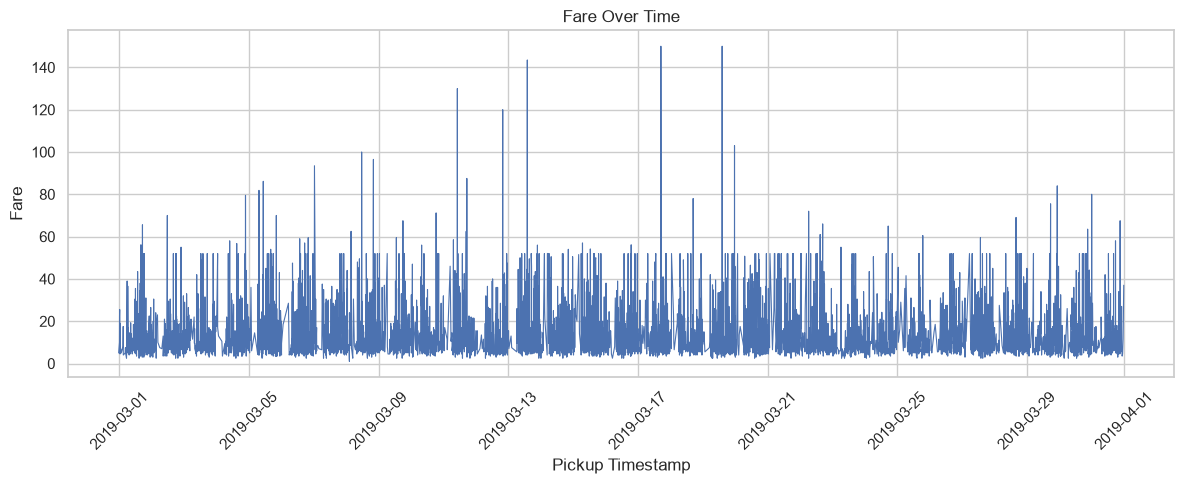

In [5]:
df["pickup"] = pd.to_datetime(df["pickup"])
df_sorted = df.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(df_sorted["pickup"], df_sorted["fare"], linewidth=0.8)
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

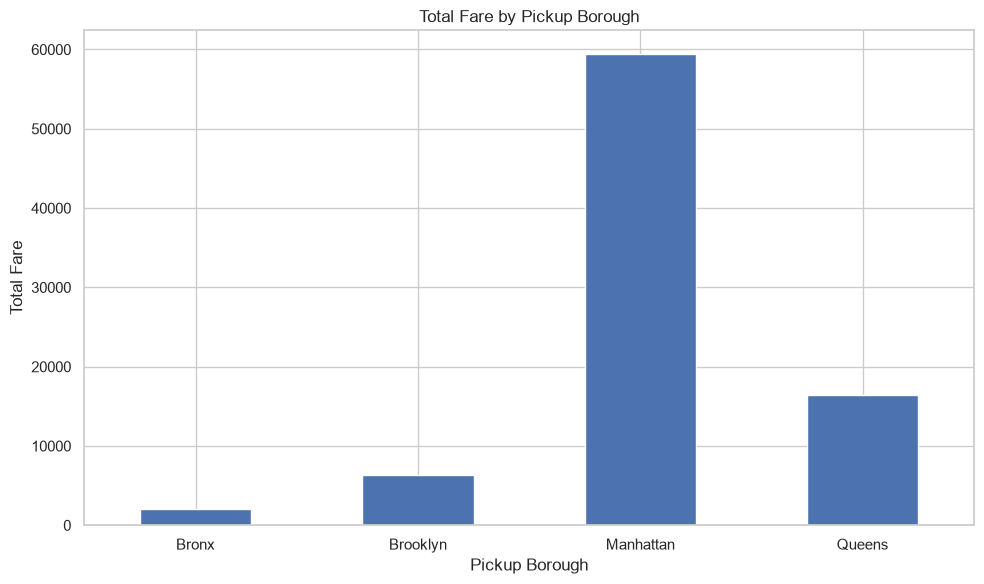

In [6]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()

borough_fare.plot(kind="bar")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

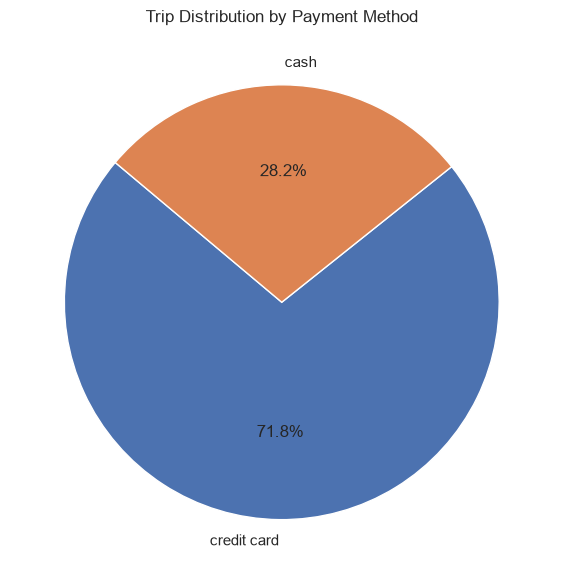

In [7]:
payment_counts = df["payment"].value_counts()

payment_counts.plot(kind="pie", autopct="%1.1f%%", startangle=140)
plt.title("Trip Distribution by Payment Method")
plt.ylabel("")
plt.tight_layout()
plt.show()

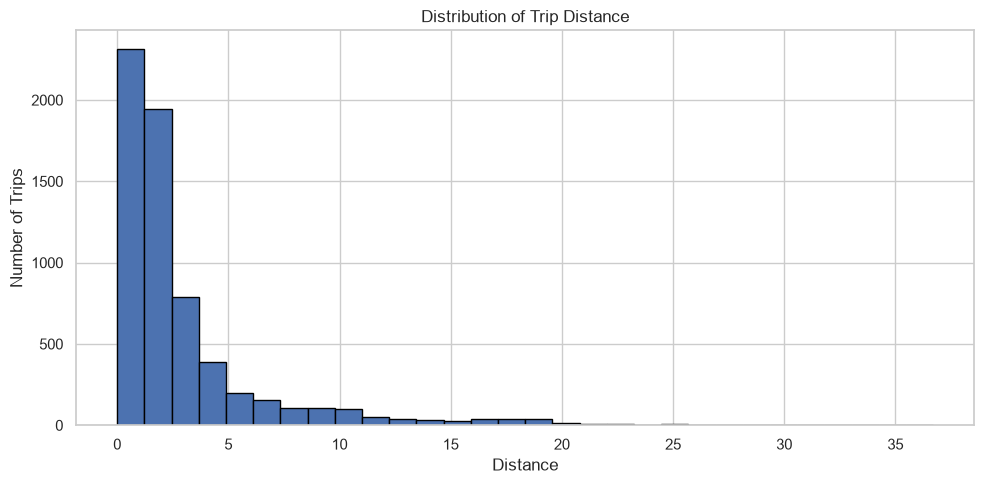

In [8]:
plt.figure(figsize=(10, 5))
plt.hist(df["distance"], bins=30, edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

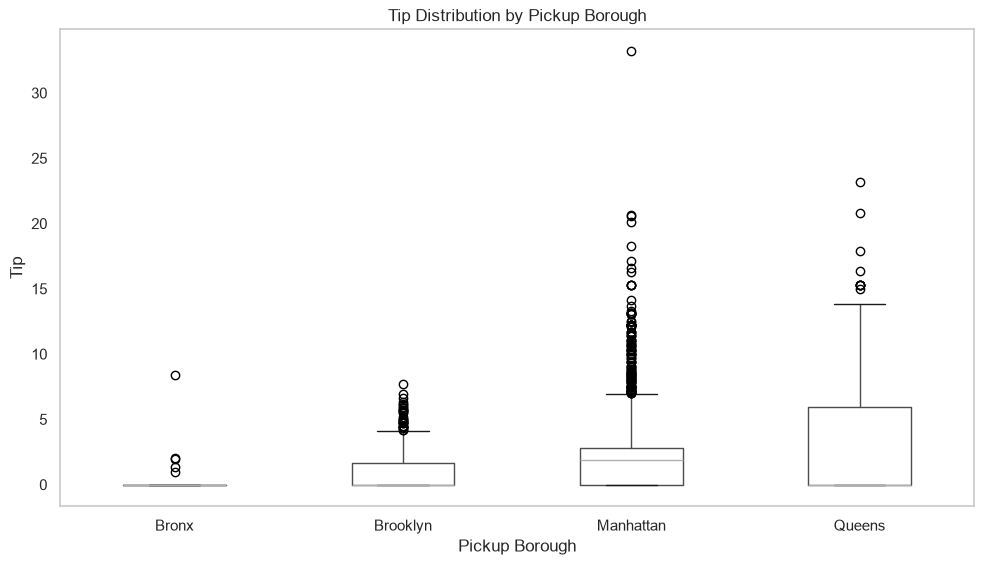

In [9]:
df.boxplot(column="tip", by="pickup_borough", grid=False)
plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

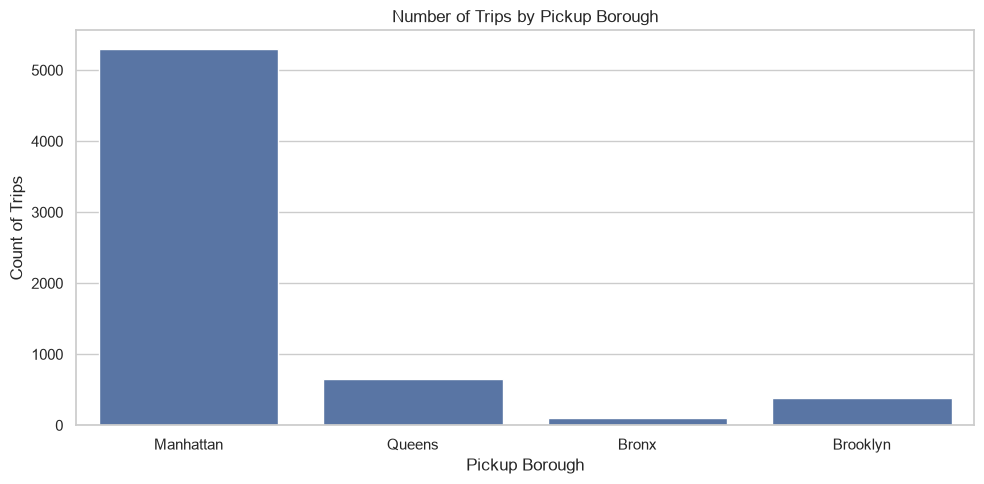

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Count of Trips")
plt.tight_layout()
plt.show()

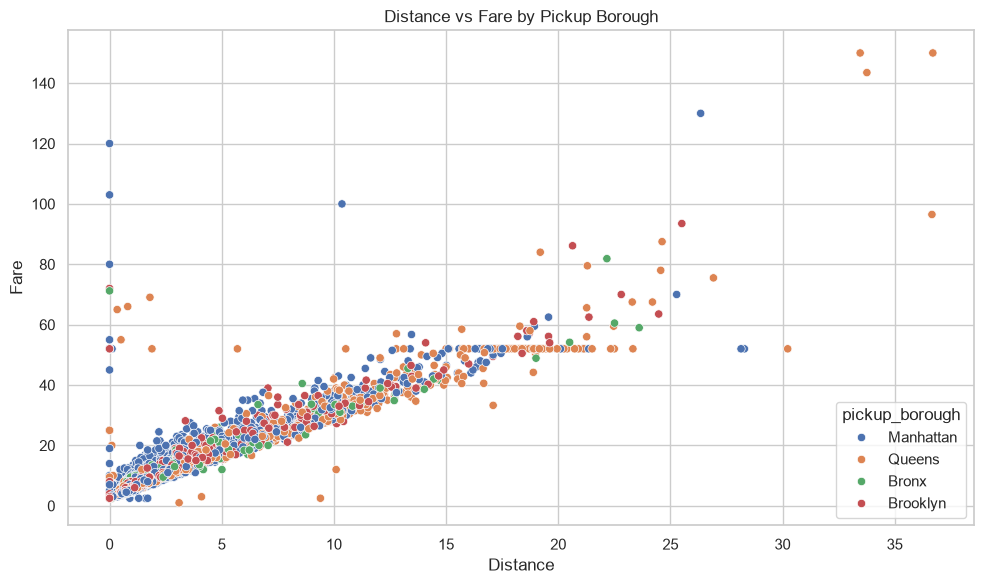

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough")
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

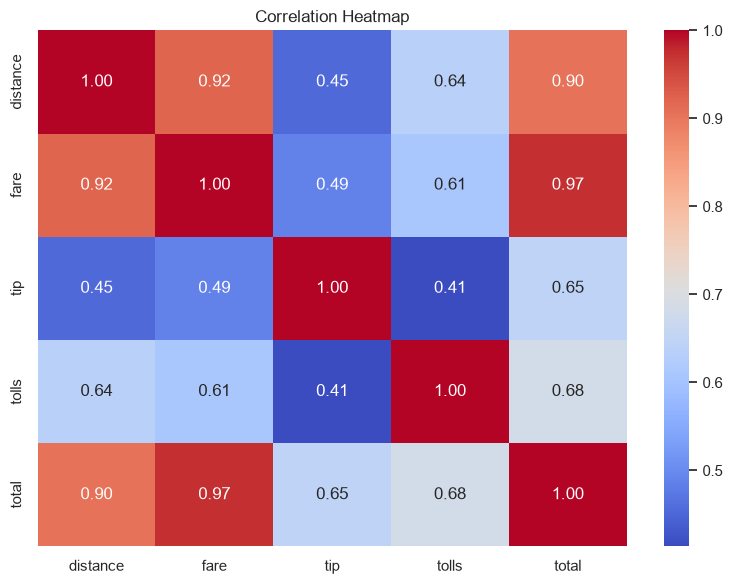

In [12]:
corr_cols = ["distance", "fare", "tip", "tolls", "total"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

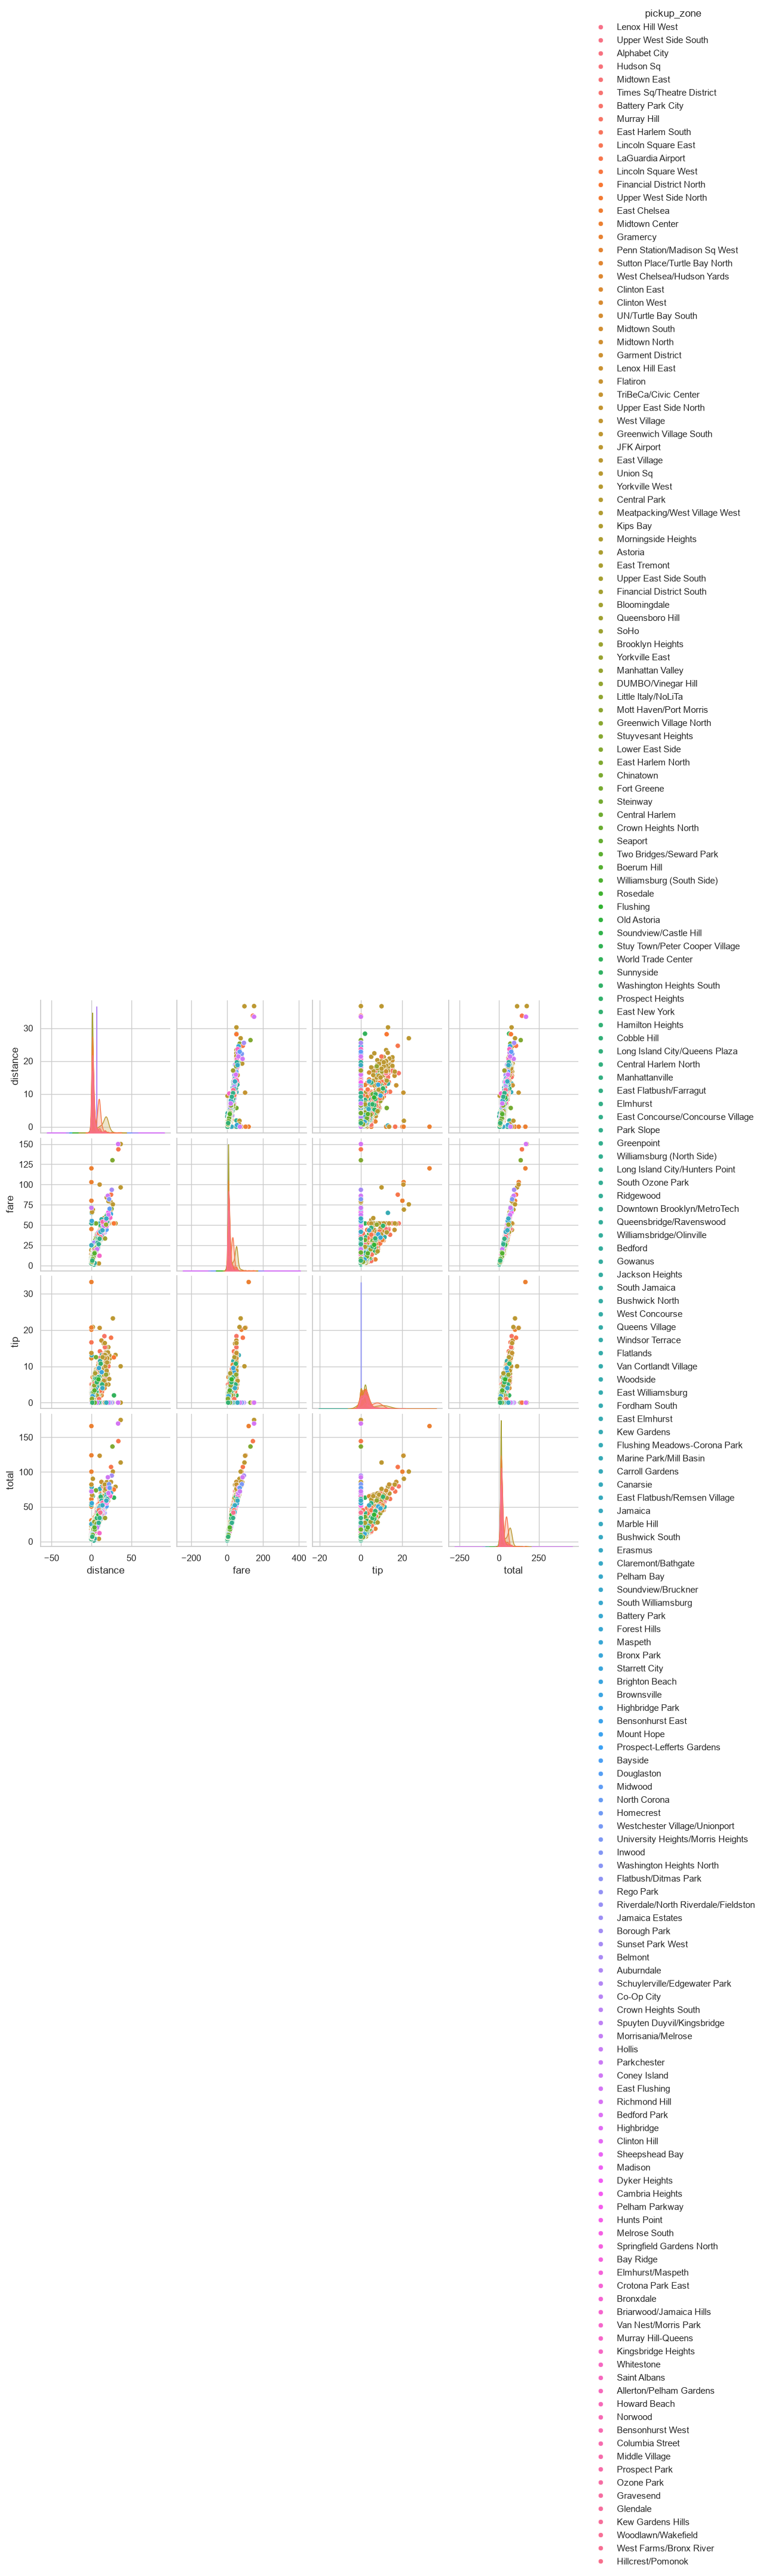

In [13]:
pair_cols = ["distance", "fare", "tip", "total", "pickup_zone"]
sns.pairplot(df[pair_cols], hue="pickup_zone")
plt.show()

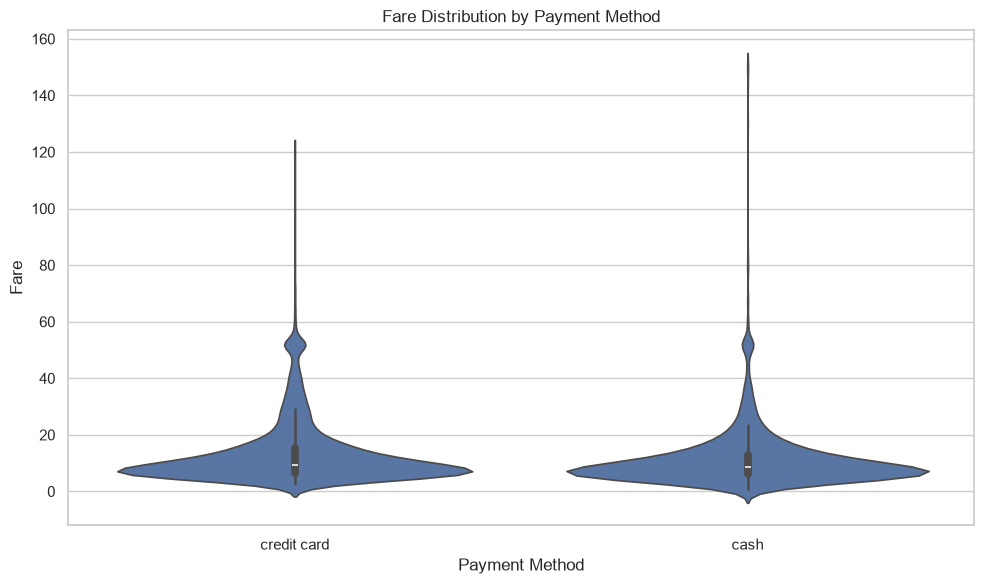

In [14]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x="payment", y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()